---
title: "L6-06 · Bell inequalities and causal inequalities"
short_title: "Bell inequalities and causal inequalities"
subtitle: "A Bell inequality tests whether correlations between two separated wings fit a classical common cause; a causal inequality tests whether correlations between two laboratories fit any definite causal order; different null models give different certificates."
description: "Derive the local, quantum and no-signaling ceilings of the CHSH expression and the 3/4 ceiling of the OCB causal game, and state exactly which model class each violation rules out."
tags: [level-6, coursebook]
---

(lesson-l6-06)=

:::{div}
:class: qcai-meta
![Level 6 icon](../../_static/icons/qicon-level-6.svg) **Level 6 · Graduate** · about 120 minutes  
**Big idea.** A Bell inequality tests whether correlations between two separated wings fit a classical common cause; a causal inequality tests whether correlations between two laboratories fit any definite causal order; different null models give different certificates.  
**Before this lesson.** [L5-08](#lesson-l5-08), [L6-02](#lesson-l6-02), [L6-05](#lesson-l6-05)  
**Lab.** [Entanglement and Bell tests](../../labs/06-entanglement-bell.ipynb)
:::

## What you will be able to do

- Prove $|S| \le 2$ for local models and $|S| \le 2\sqrt{2}$ for quantum models of the CHSH expression, and exhibit the PR box with $S = 4$.
- Draw and justify the images of the local, quantum and no-signaling sets in the plane of two CHSH expressions $(S_1, S_2)$.
- Prove the 3/4 bound of the OCB game for every causally ordered strategy and verify that the process $W_{\rm OCB}$ reaches $(2+\sqrt{2})/4$ under a stated Choi convention.
- For a given violation, state the null model it rejects, the assumptions it rests on, and at least one conclusion it does not support.

## Why this matters

Two different experiments can both print the sentence "inequality violated". In a Bell test, two wings far apart choose settings and record outcomes; the violation says the data cannot come from a classical common cause that is independent of the settings. In a causal-inequality test, two laboratories each receive a system once and send one out; the violation says the data cannot come from any definite order of the two laboratories. The words are the same; the hypotheses being rejected are not.

The confusion is costly. A Bell violation does not show indefinite causal order, and a process that has no definite order need not violate any causal inequality. This lesson derives both kinds of bound from first principles, draws the geometry of the Bell case as three nested shapes, and computes one causal game exactly. The goal is a habit: before reading any violation, name the null model and its assumptions.

:::{dropdown} Key terms

**Behavior**
: The table of conditional probabilities $p(a, b \mid x, y)$ of outcomes given settings in a two-party experiment.

**Local polytope**
: The set of behaviors of the form $\sum_\lambda p(\lambda)\, p(a \mid x, \lambda)\, p(b \mid y, \lambda)$: a classical common cause $\lambda$, independent of the settings, with local responses. It is the convex hull of finitely many deterministic behaviors.

**No-signaling set**
: Behaviors whose marginals satisfy $p(a \mid x, y) = p(a \mid x)$ and $p(b \mid x, y) = p(b \mid y)$: no setting changes the far outcome statistics.

**PR box**
: The no-signaling behavior $p(a, b \mid x, y) = 1/2$ when $a \oplus b = xy$ and 0 otherwise (bits), which reaches $S = 4$.

**Causal inequality**
: A bound on a game's success probability that holds for every strategy in which the two laboratories act in a definite order, or a probabilistic mixture of definite orders.

**Process matrix**
: An operator $W$ on the input and output spaces of local laboratories that gives joint probabilities $\operatorname{Tr}[W(M_A \otimes M_B)]$ for every choice of local operations, without assuming a global causal order.

:::


In [1]:
import sys, pathlib, subprocess
here = pathlib.Path.cwd()
root = next((p for p in [here, *here.parents] if (p / "qcai").is_dir()), None)
if root is None:  # for example on Google Colab: fetch the course's small teaching package
    root = pathlib.Path("quantum-causal-ai")
    if not root.exists():
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/pozapas/quantum-causal-ai.git", str(root)], check=True)
    root = root.resolve()
sys.path.insert(0, str(root))
from qcai.viz import show as _show, show_mpl as _show_mpl
from qcai.lessonfigs import l6_06 as _lessonfigs

## Two null models

In the Bell scenario (the same one as [L5-08](#lesson-l5-08)), Alice chooses a setting $x \in \{0, 1\}$ and records $a \in \{+1, -1\}$; Bob chooses $y$ and records $b$. Read as a causal graph, the classical hypothesis has a hidden common cause $\Lambda$ of both outcomes, settings that are independent of $\Lambda$, and no arrow from a setting to the far outcome [@bell; @woodspekkens]. Its behaviors are

$$
p(a, b \mid x, y) = \sum_{\lambda} p(\lambda)\, p(a \mid x, \lambda)\, p(b \mid y, \lambda).
$$ (eq-l6-06-local)

:::{prf:definition} Local, quantum and no-signaling sets
:label: def-l6-06-sets
Fix two settings and two outcomes per party. The **local set** $\mathcal{L}$ is the set of behaviors of the form [](#eq-l6-06-local). The **quantum set** $\mathcal{Q}$ is the set of behaviors $p(a, b \mid x, y) = \operatorname{Tr}[(E_{a|x} \otimes F_{b|y})\rho]$ for some state $\rho$ and POVMs $\{E_{a|x}\}$, $\{F_{b|y}\}$ on a tensor product of finite-dimensional spaces. The **no-signaling set** $\mathcal{NS}$ is the set of behaviors whose single-party marginals do not depend on the other party's setting. Then $\mathcal{L} \subseteq \mathcal{Q} \subseteq \mathcal{NS}$, and both inclusions are strict.
:::

The causal-inequality scenario of Oreshkov, Costa and Brukner [@ocb] has a different shape. Each laboratory receives one system (Alice's input $A_1$, Bob's $B_1$), acts on it, and sends one system out ($A_2$, $B_2$). Alice tosses a bit $a$; Bob tosses bits $b$ and $b'$. No spatial separation is assumed. The classical hypothesis is that the two laboratories act in a definite order, $A \prec B$ or $B \prec A$, or in a probabilistic mixture of the two.

```{mermaid}
graph LR
  subgraph Bell["Bell: classical common cause"]
    X[setting x] --> A[outcome a]
    L((hidden L)) --> A
    L --> B[outcome b]
    Y[setting y] --> B
  end
  subgraph Order["OCB: definite order A before B"]
    a1[bit a] --> AL[Alice lab]
    AL -->|system| BL[Bob lab]
    b1[bits b, b2] --> BL
    AL --> xg[guess x]
    BL --> yg[guess y]
  end
```

*Left: the null model of a Bell test, a hidden classical common cause $\Lambda$ (drawn L) with no arrow from a setting to the far outcome. Right: one of the two null models of the OCB game, Alice's laboratory before Bob's (b2 stands for $b'$); the other has the arrow reversed. Mixtures of the two are also allowed.*

## The three ceilings of CHSH

Write $E_{xy} = p(a = b \mid x, y) - p(a \ne b \mid x, y)$ for the correlator and use the convention

$$
S = E_{00} + E_{01} + E_{10} - E_{11}.
$$ (eq-l6-06-chsh)

:::{prf:theorem} CHSH ceilings
:label: thm-l6-06-ceilings
(i) Every behavior in $\mathcal{L}$ has $|S| \le 2$ [@chsh]. (ii) Every behavior in $\mathcal{Q}$ has $|S| \le 2\sqrt{2}$ [@tsirelson1980], and $|\Phi^+\rangle$ with suitable measurements reaches $2\sqrt{2}$. (iii) Every behavior in $\mathcal{NS}$ has $|S| \le 4$, and the PR box reaches 4 [@popescu1994].
:::

:::{prf:proof}
(i) and (ii) are proved in full in [L5-08](#lesson-l5-08), and (i) is derived from the causal graph in [L6-01](#lesson-l6-01); we keep only the two lines used below. (i) $S$ is linear and $\mathcal{L}$ is the convex hull of the 16 deterministic behaviors [@fine1982], for which $S = a_0(b_0 + b_1) + a_1(b_0 - b_1) = \pm 2$. (ii) For $\pm 1$ observables, $C = A_0 \otimes (B_0 + B_1) + A_1 \otimes (B_0 - B_1)$ satisfies $C^2 = 4I - [A_0, A_1]\otimes[B_0, B_1]$, and each commutator has norm at most 2, so $|S| \le \|C\| \le 2\sqrt{2}$ [@tsirelson1980; @nielsenchuang]. With $|\Phi^+\rangle$ and observables $\cos t\, Z + \sin t\, X$ (Bloch-sphere angles, twice the polarizer angles of L5-08), $E_{xy} = \cos(\alpha_x - \beta_y)$, and $\alpha = (0, \pi/2)$, $\beta = (\pi/4, -\pi/4)$ give $2\sqrt{2}$.

(iii) Each $|E_{xy}| \le 1$, so $|S| \le 4$. The PR box has $E_{00} = E_{01} = E_{10} = 1$ and $E_{11} = -1$, so $S = 4$, and each marginal equals $1/2$ for every pair of settings, so it is no-signaling.
:::

:::{figure} ../../_static/animations/l6_06_three_ceilings.mp4
:alt: The CHSH expression, the factorization that proves the local bound 2, the square of the CHSH operator that proves the quantum bound 2 root 2, the PR box with value 4, and a number line with the three ceilings.
:width: 100%

One number, three ceilings: 2 for local models, $2\sqrt{2}$ for quantum models, 4 for the PR box.
:::

:::{dropdown} What the animation shows
The animation writes $S = E_{00} + E_{01} + E_{10} - E_{11}$. For a local deterministic model it rewrites $S$ as $a_0(b_0 + b_1) + a_1(b_0 - b_1)$ and notes that one bracket is 0 and the other $\pm 2$, so $|S| \le 2$. For quantum observables with eigenvalues $\pm 1$ it forms $C = A_0\otimes(B_0 + B_1) + A_1\otimes(B_0 - B_1)$ and its square $C^2 = 4I - [A_0, A_1]\otimes[B_0, B_1]$; the commutator norms are at most 2, so $\|C^2\| \le 8$ and $|S| \le 2\sqrt{2}$. For the PR box, $E_{00} = E_{01} = E_{10} = 1$ and $E_{11} = -1$ give $S = 4$ with all marginals equal to $1/2$. A number line from 0 to 4 marks local 2, quantum $2\sqrt{2} \approx 2.83$ and no-signaling 4.
:::

:::{prf:remark} The same numbers as a game
:label: rem-l6-06-game
With bits instead of $\pm 1$ outcomes, call the round won when $a \oplus b = xy$. With uniformly random settings the winning probability is $\tfrac14\sum_{xy}\tfrac12(1 \pm E_{xy}) = \tfrac12 + S/8$. The three ceilings become $3/4$ (local), $(2+\sqrt{2})/4 \approx 0.854$ (quantum) and 1 (PR box).
:::

Check the three ceilings: enumerate all 16 deterministic local strategies, compute the quantum value with `qcai.science.chsh_value` (observables $\cos t\,Z + \sin t\,X$), test the operator identity for random observables, and build the PR box.


In [2]:
import itertools, math
import numpy as np
from qcai import science as s

# CHSH convention: S = E00 + E01 + E10 - E11, outcomes +1/-1.
def S_of(E):
    return E[0] + E[1] + E[2] - E[3]

# 1) local deterministic strategies: a_x, b_y in {+1, -1}
local = [S_of((a0*b0, a0*b1, a1*b0, a1*b1)) for a0, a1, b0, b1 in itertools.product((1, -1), repeat=4)]
print("largest local |S| over 16 deterministic strategies:", max(abs(v) for v in local))

# 2) quantum: |Phi+>, observables cos(t) Z + sin(t) X, Alice 0 and pi/2, Bob pi/4 and -pi/4
rho = s.dm(s.bell_state("phi+"))
S_q = s.chsh_value(rho, 0, math.pi / 2, math.pi / 4, -math.pi / 4)
print("quantum S:", round(S_q, 6), " 2*sqrt(2) =", round(2 * math.sqrt(2), 6))

# 3) the operator identity C^2 = 4I - [A0, A1] (x) [B0, B1] for random +1/-1 observables
rng = np.random.default_rng(7)
def random_pm1(d=2):
    M = rng.normal(size=(d, d)) + 1j * rng.normal(size=(d, d))
    w, V = np.linalg.eigh(M + M.conj().T)
    return V @ np.diag([1, -1]) @ V.conj().T
A0, A1, B0, B1 = (random_pm1() for _ in range(4))
C = np.kron(A0, B0 + B1) + np.kron(A1, B0 - B1)
comm = lambda P, Q: P @ Q - Q @ P
print("C^2 identity holds:", np.allclose(C @ C, 4 * np.eye(4) - np.kron(comm(A0, A1), comm(B0, B1))))
print("largest |eigenvalue| of this C:", round(max(abs(np.linalg.eigvalsh(C))), 4), "<= 2.8284")

# 4) the PR box: p(a, b | x, y) = 1/2 if a XOR b = x AND y (bits), else 0
pr = {(a, b, x, y): 0.5 * ((a ^ b) == (x & y)) for a, b, x, y in itertools.product((0, 1), repeat=4)}
E = [sum((-1) ** (a ^ b) * pr[a, b, x, y] for a in (0, 1) for b in (0, 1)) for x in (0, 1) for y in (0, 1)]
marg_ok = all(abs(sum(pr[a, b, x, y] for b in (0, 1)) - 0.5) < 1e-12 for a in (0, 1) for x in (0, 1) for y in (0, 1))
print("PR box correlators", E, " S =", S_of(E), " Alice marginals all 1/2:", marg_ok)

assert max(abs(v) for v in local) == 2 and abs(S_q - 2 * math.sqrt(2)) < 1e-12 and S_of(E) == 4 and marg_ok

largest local |S| over 16 deterministic strategies: 2
quantum S: 2.828427  2*sqrt(2) = 2.828427
C^2 identity holds: True
largest |eigenvalue| of this C: 2.2514 <= 2.8284
PR box correlators [1.0, 1.0, 1.0, -1.0]  S = 4.0  Alice marginals all 1/2: True


## A picture of the three sets

The full behavior space is eight-dimensional, so we look at a two-dimensional shadow. Restrict to behaviors with uniform marginals; they are described by the four correlators $E_{xy}$, and any $E \in [-1, 1]^4$ is no-signaling. Project onto two CHSH expressions with the minus sign in different places:

$$
S_1 = E_{00} + E_{01} + E_{10} - E_{11}, \qquad S_2 = -E_{00} + E_{01} + E_{10} + E_{11}.
$$ (eq-l6-06-s1s2)

:::{prf:proposition} The three images
:label: prop-l6-06-images
Under the map $E \mapsto (S_1, S_2)$, the local set goes to the square $|S_1|, |S_2| \le 2$, the quantum set to the disk $S_1^2 + S_2^2 \le 8$, and the no-signaling set to the diamond $|S_1| + |S_2| \le 4$. All three touch at the four points $(\pm 2, \pm 2)$.
:::

:::{prf:proof}
A linear image of a convex set is the convex hull of the images of its extreme points, so it is enough to find those images or the support function $h(\varphi) = \max (S_1\cos\varphi + S_2\sin\varphi)$.

Local: for a deterministic box, $S_1 = a_0(b_0 + b_1) + a_1(b_0 - b_1)$ and $S_2 = a_0(b_1 - b_0) + a_1(b_0 + b_1)$. If $b_0 = b_1 = b$ this is $(2a_0 b, 2a_1 b)$; if $b_0 = -b_1$ it is $(2a_1 b_0, -2a_0 b_0)$. All 16 boxes land on the corners $(\pm 2, \pm 2)$, whose hull is the square.

No-signaling: the extreme points of $[-1, 1]^4$ are the sign vectors. Those with $E_{00}E_{01}E_{10}E_{11} = +1$ are deterministic local boxes (corners of the square). Those with product $-1$ are PR-type boxes; four of them land on $(\pm 4, 0)$ or $(0, \pm 4)$ (the PR box lands on $(4, 0)$) and the other four land on the origin (for example $E = (1, -1, 1, 1)$). The hull is the diamond, and $(2, 2)$ lies on its edge.

Quantum: as in the theorem, $E_{xy} = \langle u_x, v_y\rangle$ with unit vectors $u_x = (A_x \otimes I)|\psi\rangle$ and $v_y = (I \otimes B_y)|\psi\rangle$ (real part of the inner product, which is the correlator for Hermitian $A_x, B_y$). For a direction $\varphi$ put $c = \cos\varphi - \sin\varphi$ and $d = \cos\varphi + \sin\varphi$, so $c^2 + d^2 = 2$. Then $S_1\cos\varphi + S_2\sin\varphi = \langle u_0, c\,v_0 + d\,v_1\rangle + \langle u_1, d\,v_0 - c\,v_1\rangle \le \|c\,v_0 + d\,v_1\| + \|d\,v_0 - c\,v_1\|$ by Cauchy-Schwarz. The squared norms add to $(c^2 + d^2)(\|v_0\|^2 + \|v_1\|^2) = 4$ (the cross terms cancel), so the sum of the norms is at most $\sqrt{2 \cdot 4} = 2\sqrt{2}$. Hence $h_{\mathcal Q}(\varphi) \le 2\sqrt{2}$ for every $\varphi$, which is the disk. Every boundary point is reached: with $|\Phi^+\rangle$, Alice's angles $(0, \pi/2)$ and Bob's $\beta_0 = \varphi + \pi/4$, $\beta_1 = \varphi - \pi/4$, one gets $(S_1, S_2) = 2\sqrt{2}(\cos\varphi, \sin\varphi)$.
:::

:::{figure} ../../_static/animations/l6_06_polytope_shadow.mp4
:alt: In the plane of S1 and S2, sixteen deterministic local boxes fly to the four corners of a square, a quantum strategy traces a circle of radius 2 root 2, and four PR boxes span a diamond that touches the circle where the circle touches the square.
:width: 100%

The local square, the quantum disk and the no-signaling diamond in the $(S_1, S_2)$ plane. This is a projection, so faces of the full sets can hide behind each other.
:::

:::{dropdown} What the animation shows
Axes for $S_1$ and $S_2$ run from $-4$ to 4. Sixteen blue dots, one per deterministic local box, move onto the four corners $(\pm 2, \pm 2)$ and a shaded square appears: local means $|S_1|, |S_2| \le 2$. A violet point then moves as the strategy angle $\varphi$ goes once around, using $|\Phi^+\rangle$ with Alice's angles 0 and $\pi/2$ and Bob's $\beta_0 = \varphi + \pi/4$, $\beta_1 = \varphi - \pi/4$; it traces the circle $S_1^2 + S_2^2 \le 8$ and passes $(2\sqrt{2}, 0)$. Four red PR boxes appear at $(\pm 4, 0)$ and $(0, \pm 4)$; the PR box at $(4, 0)$ is labeled. Their hull is the diamond $|S_1| + |S_2| \le 4$. A ring marks the corner $(2, 2)$, where all three shapes meet.
:::


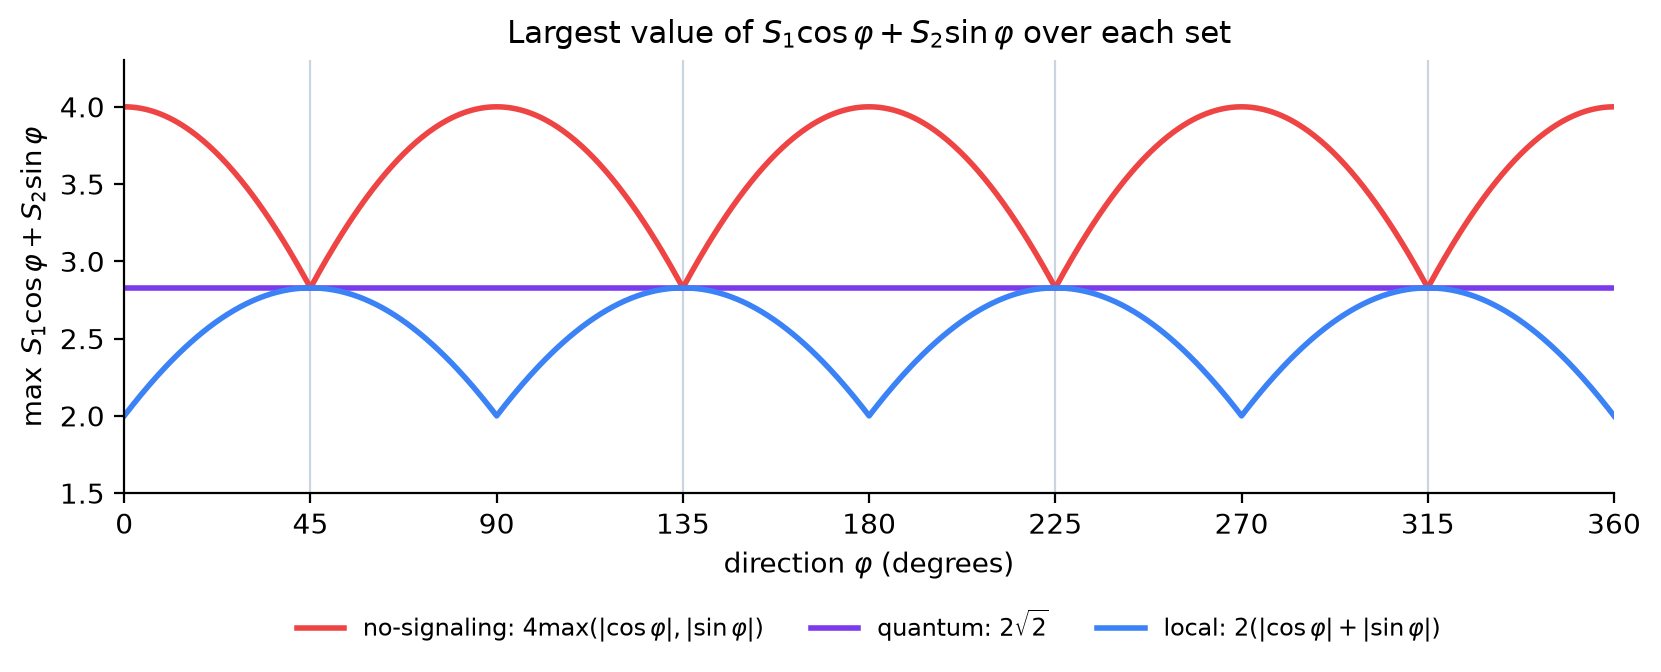

In [3]:
_show_mpl(_lessonfigs.support_functions())

*Support functions of the three images: the largest value of $S_1\cos\varphi + S_2\sin\varphi$ over each set. Each direction gives a Bell-type inequality; the three curves coincide at $45^\circ$, $135^\circ$, $225^\circ$ and $315^\circ$, where no quantum advantage exists in this projection.*

Compute the images: the 16 deterministic boxes, eight quantum points from the angle family above, and the support functions in three directions.


In [4]:
# Images of the three sets in the plane of S1 = E00 + E01 + E10 - E11 and S2 = -E00 + E01 + E10 + E11
def S12(E):
    return (E[0] + E[1] + E[2] - E[3], -E[0] + E[1] + E[2] + E[3])

corners = sorted({S12((a0*b0, a0*b1, a1*b0, a1*b1)) for a0, a1, b0, b1 in itertools.product((1, -1), repeat=4)})
print("16 local deterministic boxes land on:", corners)

phis = np.linspace(0, 2 * math.pi, 9)[:-1]
pts = []
for phi in phis:
    al, be = (0, math.pi / 2), (phi + math.pi / 4, phi - math.pi / 4)
    pts.append(S12([math.cos(al[x] - be[y]) for x in (0, 1) for y in (0, 1)]))
radii = [round(math.hypot(*p), 6) for p in pts]
print("quantum points on the circle of radius", set(radii))

# support function: largest value of S1 cos(phi) + S2 sin(phi) over each set
for deg in (0, 30, 45):
    u = (math.cos(math.radians(deg)), math.sin(math.radians(deg)))
    h_loc = max(u[0] * c[0] + u[1] * c[1] for c in corners)
    h_ns = max(u[0] * c[0] + u[1] * c[1] for c in [(4, 0), (0, 4), (-4, 0), (0, -4)])
    print(f"phi = {deg:2d} deg: local {h_loc:.4f}  quantum {2*math.sqrt(2):.4f}  no-signaling {h_ns:.4f}")

16 local deterministic boxes land on: [(-2, -2), (-2, 2), (2, -2), (2, 2)]
quantum points on the circle of radius {2.828427}
phi =  0 deg: local 2.0000  quantum 2.8284  no-signaling 4.0000
phi = 30 deg: local 2.7321  quantum 2.8284  no-signaling 3.4641
phi = 45 deg: local 2.8284  quantum 2.8284  no-signaling 2.8284


:::{warning} A projection is not a slice
The familiar textbook picture is a slice through a local deterministic box, a PR box and white noise. The picture here is a shadow of the uniform-marginal behaviors. In a shadow, a behavior that looks inside the square can still violate a CHSH inequality in a direction not shown; only the support-function statements above are exact.
:::

## A causal inequality: the OCB game

In the game of [@ocb], Alice tosses $a$, Bob tosses $b$ and $b'$, and each party produces a guess, $x$ for Alice and $y$ for Bob. If $b' = 0$, Bob must communicate $b$ to Alice, and the round is won when $x = b$; if $b' = 1$, Bob must guess Alice's bit, and the round is won when $y = a$. The success probability is

$$
p_{\rm succ} = \tfrac12\big[P(x = b \mid b' = 0) + P(y = a \mid b' = 1)\big].
$$ (eq-l6-06-psucc)

:::{prf:definition} Causally ordered strategy
:label: def-l6-06-order
A strategy is **causally ordered** if its behavior can be written $p = q\, p^{A \prec B} + (1 - q)\, p^{B \prec A}$ with $0 \le q \le 1$, where under $A \prec B$ Alice's guess $x$ is independent of Bob's bits $(b, b')$, and under $B \prec A$ Bob's guess $y$ is independent of Alice's bit $a$ (given $b, b'$). The bits $a, b, b'$ are uniform and independent, and each laboratory receives its system once.
:::

:::{prf:theorem} OCB causal inequality
:label: thm-l6-06-ocb
Every causally ordered strategy has $p_{\rm succ} \le 3/4$, and $3/4$ is reached.
:::

:::{prf:proof}
$p_{\rm succ}$ is linear in the behavior, so it suffices to treat each order. Under $A \prec B$, $x$ is independent of $b$, and $b$ is uniform, so $P(x = b \mid b' = 0) = 1/2$; the other term is at most 1. Hence $p_{\rm succ} \le \tfrac12(\tfrac12 + 1) = 3/4$. Under $B \prec A$, $y$ is independent of the uniform bit $a$, so $P(y = a \mid b' = 1) = 1/2$ and again $p_{\rm succ} \le 3/4$. A mixture with weight $q$ is at most $q \cdot 3/4 + (1 - q) \cdot 3/4$. The value is reached when Alice always sends $a$ to Bob, Bob outputs $y = a$, and Alice guesses at random.
:::

A process matrix assigns probabilities without a global order. With the convention of [@ocb], a local map $\mathcal{M}: A_1 \to A_2$ is represented by $M = [\mathcal{I} \otimes \mathcal{M}(|\phi^+\rangle\langle\phi^+|)]^{T}$ with $|\phi^+\rangle = \sum_j |jj\rangle$ unnormalized. This is $M = J^{T}$, the full transpose of the course Choi operator $J$ (see the dictionary in [L6-02](#lesson-l6-02)), while $W$ is built from untransposed course Choi operators, so the joint probability is $P = \operatorname{Tr}[W(M_A \otimes M_B)] = \operatorname{Tr}[W(J_A \otimes J_B)^{T}]$. Lessons L6-07 and L6-08 write $A_1, A_2, B_1, B_2$ as $A_I, A_O, B_I, B_O$. Write $_X W = \operatorname{Tr}_X W \otimes I_X/d_X$. A bipartite $W$ is valid when $W \ge 0$, $\operatorname{Tr} W = d_{A_2} d_{B_2}$, and $_{A_1A_2}W = {}_{A_1A_2B_2}W$, $_{B_1B_2}W = {}_{A_2B_1B_2}W$, $W = {}_{A_2}W + {}_{B_2}W - {}_{A_2B_2}W$ [@process]. The OCB process on four qubits is

$$
W_{\rm OCB} = \tfrac14\Big[I + \tfrac{1}{\sqrt2}\big(Z^{A_2}Z^{B_1} + Z^{A_1}X^{B_1}Z^{B_2}\big)\Big].
$$ (eq-l6-06-wocb)

:::{prf:proposition} The OCB process wins with probability (2+\sqrt{2})/4
:label: prop-l6-06-wocb
$W_{\rm OCB}$ is valid. With the strategy below it gives $P(y = a \mid b' = 1) = P(x = b \mid b' = 0) = (2+\sqrt{2})/4$, so $p_{\rm succ} = (2+\sqrt{2})/4 \approx 0.854 > 3/4$ [@ocb]. Alice measures $Z$ on $A_1$ (outcome $x$) and prepares $|a\rangle$ on $A_2$. If $b' = 1$, Bob measures $Z$ on $B_1$ and outputs the outcome as $y$. If $b' = 0$, Bob measures $X$ on $B_1$ with outcome $s$ and prepares the $Z$ eigenstate $|b \oplus s\rangle$ on $B_2$.
:::

:::{prf:proof}
Validity is a finite check of the five conditions, done in the code below. For the success probability: if Bob measures $Z$ on $B_1$, the term containing $X^{B_1}$ drops out, and what remains is a noisy channel from $A_2$ to $B_1$ that maps Alice's $|a\rangle$ to a state with $\langle Z\rangle = (-1)^a/\sqrt2$, so $P(y = a) = \tfrac12(1 + 1/\sqrt2) = (2+\sqrt{2})/4$. If Bob measures $X$ and re-encodes, his outcome-averaged operation $\tfrac12[I + (-1)^b X^{B_1}Z^{B_2}]$ selects the second term, which leaves a channel from Bob to Alice with the same bias, so $P(x = b) = (2+\sqrt{2})/4$ as well [@ocb]. We state only that this process reaches this value; we do not claim it is the largest value any valid process reaches.
:::

:::{figure} ../../_static/animations/l6_06_ocb_game.mp4
:alt: Alice's and Bob's laboratories as boxes, the rules of the OCB game, the derivation of the 3/4 bound for a definite order, the process matrix W_OCB, and bars comparing 3/4, 0.854 and 1.
:width: 100%

A definite order caps the OCB game at 3/4; the process $W_{\rm OCB}$ reaches $(2+\sqrt{2})/4 \approx 0.854$.
:::

:::{dropdown} What the animation shows
Two boxes stand for Alice's and Bob's laboratories, with Alice's bit $a$ and Bob's bits $b$ and $b'$, and guesses $x$ and $y$. The rules appear: if $b' = 0$ Alice must guess $b$, if $b' = 1$ Bob must guess $a$, and $p_{\rm succ} = \tfrac12[P(x = b \mid b' = 0) + P(y = a \mid b' = 1)]$. An arrow from Alice to Bob marks the order $A \prec B$: Alice acts first, so $x$ cannot depend on $b$, the first probability becomes $\tfrac12$, and the formula transforms into $p_{\rm succ} \le \tfrac12[\tfrac12 + 1] = 3/4$; the same cap holds for the reverse order and for mixtures. Then the process $W_{\rm OCB}$ is written and three bars grow: 3/4 for causal order, 0.854 for $W_{\rm OCB}$, and the ceiling 1. The last line reads $(2+\sqrt{2})/4 > 3/4$.
:::

Build $W_{\rm OCB}$, check the validity conditions, compute the success probability of the strategy above, brute-force every deterministic strategy with Alice first, and add white noise.


In [5]:
# The OCB process matrix on A1 A2 B1 B2 (inputs A1, B1; outputs A2, B2), generalized Born rule
# p = Tr[W (M_A (x) M_B)] with M = J^T, the transpose of the course Choi operator (L6-02 dictionary).
I2, Xp, Zp = np.eye(2), np.array([[0, 1], [1, 0]]), np.diag([1.0, -1.0])
k = s.kron
W = (k(I2, I2, I2, I2) + (k(I2, Zp, Zp, I2) + k(Zp, I2, Xp, Zp)) / math.sqrt(2)).real / 4

def trace_replace(W, sub):
    """Trace out subsystem sub (0..3) and replace it by I/2 (the operation written _X W in the text)."""
    T = W.reshape([2] * 8)
    idx = list(range(8)); idx[sub + 4] = idx[sub]
    keep = [i for i in range(8) if i not in (sub, sub + 4)]
    red = np.einsum(T, idx, keep)
    return np.einsum(red, keep, np.eye(2) / 2, [sub, sub + 4], list(range(8))).reshape(16, 16)

def tr(W, *subs):
    for q in subs:
        W = trace_replace(W, q)
    return W

A1, A2, B1, B2 = 0, 1, 2, 3
valid = [np.linalg.eigvalsh(W).min() > -1e-12, abs(np.trace(W) - 4) < 1e-12,
         np.allclose(tr(W, A1, A2), tr(W, A1, A2, B2)), np.allclose(tr(W, B1, B2), tr(W, A2, B1, B2)),
         np.allclose(W, tr(W, A2) + tr(W, B2) - tr(W, A2, B2))]
print("W_OCB valid (positive, trace 4, three linear conditions):", all(valid))

P = lambda v: np.outer(v, v) / np.dot(v, v)
z = [P(np.array([1.0, 0])), P(np.array([0, 1.0]))]
xb = [P(np.array([1.0, 1])), P(np.array([1.0, -1]))]

def p_succ(W):
    total = 0.0
    for a, b, bp in itertools.product((0, 1), repeat=3):
        for x, y in itertools.product((0, 1), repeat=2):
            # measure-and-prepare map: course Choi J = Pi^T (x) sigma, and it enters as M = J^T
            MA = np.kron(z[x].T, z[a]).T                  # measure Z on A1 (outcome x), prepare |a> on A2
            if bp == 1:                                   # Bob must guess a: measure Z on B1, guess y
                MB = np.kron(z[y].T, I2 / 2).T
                win = (y == a)
            else:                                         # Alice must guess b: Bob measures X, sends b XOR y in Z
                MB = np.kron(xb[y].T, z[b ^ y]).T
                win = (x == b)
            total += np.trace(W @ np.kron(MA, MB)) * win / 8
    return total

print("OCB success probability:", round(p_succ(W), 6), " (2 + sqrt 2)/4 =", round((2 + math.sqrt(2)) / 4, 6))

# Best deterministic strategy with a definite order (A before B: x depends on a only; y on a, b, b').
best = 0.0
for f in itertools.product((0, 1), repeat=2):                 # x = f[a]
    for g in itertools.product((0, 1), repeat=8):             # y = g[a, b, b']
        ps = sum(((f[a] == b) if bp == 0 else (g[4 * a + 2 * b + bp] == a))
                 for a, b, bp in itertools.product((0, 1), repeat=3)) / 8
        best = max(best, ps)
print("best success with A before B:", best)

# White noise: W(v) = v W_OCB + (1 - v) I/4 is valid; success 1/2 + v sqrt(2)/4 exceeds 3/4 iff v > 1/sqrt(2)
for v in (0.6, 1 / math.sqrt(2), 0.8):
    print(f"v = {v:.4f}: p = {p_succ(v * W + (1 - v) * np.eye(16) / 4):.4f}")
assert all(valid) and abs(p_succ(W) - (2 + math.sqrt(2)) / 4) < 1e-12 and best == 0.75

W_OCB valid (positive, trace 4, three linear conditions): True
OCB success probability: 0.853553  (2 + sqrt 2)/4 = 0.853553
best success with A before B: 0.75
v = 0.6000: p = 0.7121
v = 0.7071: p = 0.7500
v = 0.8000: p = 0.7828


## What a violation certifies, and what it does not

Both tests are statistical hypothesis tests against a stated null model. The table below is the habit this lesson is after.

:::{important} Read the null model first
**CHSH value above 2.** Rejects [](#eq-l6-06-local): a classical common cause independent of the settings, with no influence from a setting to the far outcome, given fair sampling of the recorded rounds. If one also assumes quantum theory, it certifies that the shared state was entangled, because separable states give local behaviors. It does not show indefinite causal order, and any value up to $2\sqrt{2}$ is consistent with quantum theory.

**OCB success above 3/4.** Rejects every causally ordered strategy (and mixtures of orders) in which each laboratory receives its system once and the bits are uniform and independent. It does not say anything about locality or hidden common causes, and a value at or below 3/4 does not show that the process has a definite order.
:::

The last point is sharp. Araújo and coauthors show that the quantum switch is causally nonseparable (it is not a mixture of ordered processes), yet it does not violate any causal inequality [@process; @switch]. Detecting its nonseparability needs a **causal witness**: an operator inequality that assumes the instruments are known, which a device-independent causal inequality does not assume.


In [6]:
_show(_lessonfigs.noise_explorer())

**Explore.** Mix the ideal resources with white noise of weight $1 - v$. Left: the quantum points of the Werner state shrink toward the center and leave the square only when $v > 1/\sqrt2$. Right: CHSH $S/2$ and the OCB success divided by $3/4$ cross 1 at the same visibility.

:::{dropdown} What the figure shows
The first panel shows the local square, the quantum circle of radius $2\sqrt{2}$ and the no-signaling diamond in the $(S_1, S_2)$ plane, with a ring of 25 orange points at radius $2\sqrt{2}v$: the images of the Werner state $v|\Phi^+\rangle\langle\Phi^+| + (1-v)I/4$ under the angle family of the lesson. The second panel has two bars: $S/2 = \sqrt2 v$ for the Werner state, and $p_{\rm succ}/(3/4)$ for the noisy process $vW_{\rm OCB} + (1-v)I/4$, whose success is $1/2 + v\sqrt2/4$. A dashed line at 1 marks the classical bound. At $v = 1$ the bars read 1.414 and 1.138; at $v = 0.7$ both are just below 1.
:::

:::{prf:remark} Beyond the Bell graph
:label: rem-l6-06-beyond
Bell's graph is one causal structure among many. Fritz studies correlation scenarios such as the triangle, with three sources and no settings [@fritz2012]; the inflation technique gives tests of compatibility with such latent structures [@inflation]; and entropic inequalities give constraints that apply to classical and quantum causal structures alike [@chaves]. Each comes with its own null model, so the habit above applies unchanged.
:::

## Worked example

:::{admonition} Reading two reported numbers
:class: tip

A group reports CHSH $S = 2.6$ from two wings with independently chosen settings, and separately a process-matrix experiment with OCB success $0.80$. For each, which null model is rejected, by how much, and what would you need to call the second one a causal-inequality violation?

1. CHSH: the local ceiling is 2 and the quantum ceiling is $2\sqrt{2} \approx 2.83$. $S = 2.6$ exceeds 2 by $0.6$, so (given the setting-independence, locality and fair-sampling assumptions, and a confidence interval excluding 2) it rejects the classical common-cause model [](#eq-l6-06-local). It is consistent with quantum theory, since $2.6 < 2.83$.
2. In game form the CHSH result is a win rate of $1/2 + 2.6/8 = 0.825$, above the local $0.75$ and below the quantum $0.854$.
3. OCB: the causal ceiling is $3/4$, and $0.80$ exceeds it. Under the white-noise model of the code, $1/2 + v\sqrt2/4 = 0.80$ gives $v = 1.2/\sqrt2 \approx 0.849 > 1/\sqrt2$.
4. To call it a causal-inequality violation, the number must come from the game itself: uniform independent bits $a, b, b'$, each laboratory receiving its system once, and only the recorded guesses used, with no trust in the instruments. A value computed from a reconstructed $W$ under trusted measurements is a witness-type statement, not a device-independent violation.

**Result.** The CHSH number rejects a classical common cause; the OCB number, if obtained as a device-independent game, rejects every definite order. Neither conclusion implies the other.
:::

## Exercises

**1. (Core)** Show that the deterministic strategy $a_0 = a_1 = b_0 = b_1 = +1$ gives $S = 2$, and find a deterministic strategy with $S = -2$.

:::{dropdown} Solution
All correlators are 1, so $S = 1 + 1 + 1 - 1 = 2$. Flipping only $b_1$ to $-1$ gives $E_{00} = 1$, $E_{01} = -1$, $E_{10} = 1$, $E_{11} = -1$, so $S = 1 - 1 + 1 + 1 = 2$; flipping only $b_0$ instead gives $E = (-1, 1, -1, 1)$ and $S = -1 + 1 - 1 - 1 = -2$.
:::

**2. (Core)** Compute $(S_1, S_2)$ for the PR box variant $p(a, b \mid x, y) = 1/2$ when $a \oplus b = xy \oplus x$ (bits) and 0 otherwise.

:::{dropdown} Solution
The correlator is $E_{xy} = (-1)^{xy \oplus x}$: $E_{00} = 1$, $E_{01} = 1$, $E_{10} = -1$, $E_{11} = 1$. Then $S_1 = 1 + 1 - 1 - 1 = 0$ and $S_2 = -1 + 1 - 1 + 1 = 0$. It projects to the origin: it violates the CHSH inequality with the minus sign on $E_{10}$ (value $1 + 1 + 1 + 1 = 4$), a direction not visible in this projection.
:::

**3. (Stretch)** For the Werner state $\rho_v = v|\Phi^+\rangle\langle\Phi^+| + (1 - v)I/4$ (locally equivalent to Werner's family [@werner1989]), show that the angle family of the lesson gives $(S_1, S_2) = 2\sqrt{2}v(\cos\varphi, \sin\varphi)$ and find the range of $v$ in which some $\varphi$ violates a CHSH inequality.

:::{dropdown} Solution
The maximally mixed part has all correlators 0, so every correlator is multiplied by $v$ and $(S_1, S_2)$ scales by $v$. The point leaves the square $|S_1|, |S_2| \le 2$ when $2\sqrt{2}v\max(|\cos\varphi|, |\sin\varphi|) > 2$; the best direction is $\varphi = 0$, giving $v > 1/\sqrt2 \approx 0.707$. (For this state, $1/\sqrt2$ is also the threshold of the largest CHSH value over all measurements, by the Horodecki criterion used in `qcai.science.horodecki_max_chsh`.)
:::

**4. (Stretch)** Show that the noisy process $W(v) = vW_{\rm OCB} + (1 - v)I/4$ is valid for $0 \le v \le 1$ and that the OCB strategy wins with probability $1/2 + v\sqrt2/4$.

:::{dropdown} Solution
$I/4$ is valid: it is positive, has trace $4 = d_{A_2}d_{B_2}$, and satisfies the three linear conditions because tracing and replacing any subsystem leaves it unchanged. The validity conditions are linear equalities plus positivity, so a convex combination of valid processes is valid. Under $I/4$ every input is maximally mixed and independent of everything, so each guess is right with probability $1/2$. By linearity, $p_{\rm succ} = v(2+\sqrt{2})/4 + (1 - v)/2 = 1/2 + v\sqrt2/4$.
:::

**5. (Challenge)** Suppose Bob's observables anticommute, $B_0B_1 + B_1B_0 = 0$. Show that $S_1\cos\varphi + S_2\sin\varphi$ is then an ordinary CHSH expression for a new pair of $\pm 1$ observables of Bob, so it is at most $2\sqrt{2}$, and explain why the general proof in the lesson uses Cauchy-Schwarz instead.

:::{dropdown} Solution
With $c = \cos\varphi - \sin\varphi$ and $d = \cos\varphi + \sin\varphi$, $S_1\cos\varphi + S_2\sin\varphi = \langle A_0 \otimes (cB_0 + dB_1) + A_1 \otimes (dB_0 - cB_1)\rangle$. Put $B_\pm' = (cB_0 + dB_1 \pm (dB_0 - cB_1))/2$. When $B_0$ and $B_1$ anticommute, $B_\pm'$ are $\pm 1$ observables (their squares are $\tfrac14(c \pm d)^2 + \tfrac14(d \mp c)^2 = \tfrac12(c^2 + d^2) = 1$ times $I$), and the expression is the CHSH operator $A_0 \otimes (B_+' + B_-') + A_1 \otimes (B_+' - B_-')$, bounded by $2\sqrt{2}$. In general $B_0, B_1$ need not anticommute, which is why the lesson's proof uses Cauchy-Schwarz instead: it gives $\le \|cv_0 + dv_1\| + \|dv_0 - cv_1\| \le 2\sqrt{2}$ without any commutation assumption.
:::

**6. (Challenge)** A colleague claims: "Our process-tomography data show $W$ is causally nonseparable, so our setup violates a causal inequality." Give two independent reasons this does not follow.

:::{dropdown} Solution
First, tomography assumes the local instruments are characterized, so the conclusion is a witness statement about $W$ under trusted devices, not a device-independent bound on observed guesses. Second, nonseparability does not imply a causal-inequality violation at all: the quantum switch is causally nonseparable but violates no causal inequality [@process]. A causal-inequality claim needs the game played with uniform independent bits, one use of each laboratory, and a success rate whose confidence interval lies above the causal bound.
:::

## Check your understanding

**1. Which model does a CHSH value of 2.5 reject, given the standard assumptions?**

- **A.** Every definite causal order between the two wings
- **B.** Every no-signaling model
- **C.** Quantum theory
- **D.** A classical common cause independent of the settings, with local responses

:::{dropdown} Show the answer
**D. A classical common cause independent of the settings, with local responses**

The local bound 2 is derived for [](#eq-l6-06-local). A value of 2.5 is below the quantum ceiling $2\sqrt{2}$ and the no-signaling ceiling 4, and the CHSH test makes no statement about definite causal order.
:::

**2. In the $(S_1, S_2)$ projection, which shape is the image of the quantum set?**

- **A.** The disk $S_1^2 + S_2^2 \le 8$
- **B.** The diamond $|S_1| + |S_2| \le 4$
- **C.** The disk $S_1^2 + S_2^2 \le 4$
- **D.** The square $|S_1|, |S_2| \le 2$

:::{dropdown} Show the answer
**A. The disk $S_1^2 + S_2^2 \le 8$**

Cauchy-Schwarz bounds $S_1\cos\varphi + S_2\sin\varphi$ by $2\sqrt{2}$ in every direction, and the angle family reaches every point of the circle of radius $2\sqrt{2}$, whose square is 8.
:::

**3. Why is $P(x = b \mid b' = 0) = 1/2$ for every strategy with Alice's laboratory first?**

- **A.** Bob's measurement always disturbs Alice's system
- **B.** Alice's guess cannot depend on Bob's uniformly random bit $b$
- **C.** Alice's bit $a$ is uniform
- **D.** The process matrix is positive

:::{dropdown} Show the answer
**B. Alice's guess cannot depend on Bob's uniformly random bit $b$**

Under $A \prec B$, $x$ is independent of $(b, b')$, and $b$ is a fair coin, so $x = b$ with probability exactly $1/2$. This is the step that caps the game at 3/4.
:::

**4. For a two-qubit Werner state $v|\Phi^+\rangle\langle\Phi^+| + (1-v)I/4$, what is the largest CHSH value?** *(Review of [L5-08](#lesson-l5-08))*

- **A.** $2 + v$
- **B.** $2\sqrt{2}\,v^2$
- **C.** $2\sqrt{2}\,v$
- **D.** $2v$

:::{dropdown} Show the answer
**C. $2\sqrt{2}\,v$**

The noise part contributes zero to every correlator, so every correlator, and hence every CHSH value, is scaled by $v$. The ideal maximum $2\sqrt{2}$ becomes $2\sqrt{2}v$, which beats 2 exactly when $v > 1/\sqrt2$.
:::

## Common misconceptions

- **"A Bell violation shows that the two wings had no definite causal order."** A Bell test assumes a definite spacetime arrangement and rejects a classical common cause independent of the settings. Indefinite order is a different hypothesis with a different test, the causal inequality, which has its own null model.
- **"A causally nonseparable process always violates some causal inequality."** The quantum switch is causally nonseparable yet violates no causal inequality [@process]. Its nonseparability is detected by a causal witness, which assumes known instruments.
- **"Quantum correlations fill everything allowed by no-signaling."** The PR box is no-signaling with $S = 4$, above the quantum ceiling $2\sqrt{2}$. In the $(S_1, S_2)$ projection the quantum disk sits strictly inside the no-signaling diamond except at four points.

:::{caution} Scope and limits
The CHSH bounds assume two settings and two outcomes per party, finite-dimensional tensor-product quantum models, and the conventions stated ($S = E_{00} + E_{01} + E_{10} - E_{11}$, outcomes $\pm 1$). Experimental conclusions also need setting independence, locality and fair sampling, plus finite-sample confidence intervals; none are modeled here. The $(S_1, S_2)$ picture is a projection of the uniform-marginal behaviors, not a slice. The OCB bound uses the operational assumptions in the definition of a causally ordered strategy; local operations enter as $M = J^{T}$, the transpose of the course Choi operator, as in the dictionary of [L6-02](#lesson-l6-02). We do not claim that $(2+\sqrt{2})/4$ is the largest value a valid process can reach, and we make no claim about experimental violations of causal inequalities.
:::

:::{seealso} Where this leads
Process matrices and their validity conditions are developed in [L6-07](#lesson-l6-07), and the quantum switch, a causally nonseparable process that violates no causal inequality, in [L6-08](#lesson-l6-08). The causal-compatibility view of Bell tests returns in Level 7 with latent structures beyond the Bell graph.
:::

:::{dropdown} For instructors

**Why this lesson.** Graduate students often meet Bell inequalities and causal inequalities in the same seminar and merge them. Deriving both bounds side by side, with the null model written as a causal hypothesis, separates the two programs cleanly [@bell; @chsh; @ocb; @woodspekkens].

**Teaching notes.**

- Start with the local proof (one bracket vanishes), then ask students to guess what happens when the outcomes are not fixed in advance; the operator identity answers it in two lines.
- Use the projection to discuss what pictures hide: the PR-box variant of the second exercise projects to the origin yet violates a CHSH inequality.
- For the OCB game, have students find the 3/4 strategy themselves before seeing the proof of the bound.
- Keep the conventions visible: local operations enter as $M = J^{T}$ (the dictionary in L6-02). The code applies the transpose explicitly; ask students why removing it changes nothing for these real instruments and what would change for a $Y$ measurement.

**Assessment.** The worked example and the last challenge exercise test the main habit (name the null model before reading a violation). The stretch exercises test the computations behind the noise thresholds.

**Going further.** Derive the CHSH game value $1/2 + S/8$ and compare the classical, quantum and PR values with the OCB values. Then read the validity conditions in Araújo et al. [@process] and verify that $I/4$ and $W_{\rm OCB}$ satisfy them by hand.

:::

## References

This lesson draws on [@chsh; @bell; @ocb; @process; @nielsenchuang; @woodspekkens; @switch; @tsirelson1980; @popescu1994; @fine1982; @werner1989; @fritz2012; @inflation; @chaves].

**Further reading.**

- [@fritz2012]: Correlation scenarios beyond the Bell graph, including the triangle.
- [@inflation]: A general method to test compatibility of distributions with latent causal structures.
- [@chaves]: Entropic constraints for classical and quantum causal structures.

**Next:** [L6-07 · Process matrices and validity](#lesson-l6-07)
